In [2]:

# QS World University Rankings 2026 - Data Analysis
# Author: Suzanne M. Leonard

# This Jupyter Notebook analyzes the QS World University Rankings dataset
# Performs data cleaning, exploratory data analysis, and outlier detection
# Conducts a statistical analysis with meaningful visualizations.



# QS World University Rankings 2026 - Data Analysis

## Introduction
This notebook analyzes the official QS World University Rankings 2026 dataset, which consists performance data for 1,501 universities worldwide.  
We will explore:
- Dataset structure and patterns
- Data cleaning steps (missing values, outliers, data types)
- Statistical insights and correlations
- Visual trends across metrics

The aim is to understand the global higher education landscape, identify the factors that contribute to a university's ranking, and make actionable recommendations for university leaders, professors, and administrators.


In [3]:
# Import Libraries
# We use pandas for data handling, numpy for numerical operations,
# matplotlib & seaborn for visualization.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plots for better aesthetics and readability
sns.set_theme()
pd.set_option('display.max_columns', None)  # Show all columns when displaying data


## Step 1: Load the Dataset
Load the CSV file containing the QS rankings data.  



In [4]:
# --- 2. Load Dataset ---
df = pd.read_csv('2026 QS World University Rankings.csv')

# Display the first few rows to confirm it loaded correctly
df.head()


,2026 Rank,Previous Rank,Institution Name,Country/Territory,Region,Size,Focus,Research,Status,AR SCORE,AR RANK,ER SCORE,ER RANK,FSR SCORE,FSR RANK,CPF SCORE,CPF RANK,IFR SCORE,IFR RANK,ISR SCORE,ISR RANK,ISD SCORE,ISD RANK,IRN SCORE,IRN RANK,EO SCORE,EO RANK,SUS SCORE,SUS RANK,Overall SCORE
0,1,1,Massachusetts Institute of Technology (MIT),United States of America,Americas,M,CO,VH,Private not for Profit,100.0,4,100.0,2,100.0,16,100.0,7,100.0,63,91.6,153,92.3,130,94.1,98,100.0,7,93.8,33,100
1,2,2,Imperial College London,United Kingdom,Europe,L,FO,VH,Public,99.6,22,100.0,9,99.3,42,95.0,69,100.0,74,100.0,35,100.0,22,97.5,28,95.9,68,98.3,7=,99.4
2,3,6,Stanford University,United States of America,Americas,L,FC,VH,Private not for Profit,100.0,5,100.0,3,100.0,17,99.7,24,94.2,188,73.5,261,76.1,230,96.5,49,100.0,2,95.4,19=,98.9
3,4,3,University of Oxford,United Kingdom,Europe,L,FC,VH,Public,100.0,2,100.0,4,100.0,9,91.0,98,98.8,132,98.6,80,98.7,67,100.0,1,100.0,3,77.9,198=,97.9
4,5,4,Harvard University,United States of America,Americas,L,FC,VH,Private not for Profit,100.0,1,100.0,1,98.3,50,100.0,1,79.1,300,81.4,217,60.6,335,99.4,8,100.0,1,77.8,201=,97.7


## Step 2: Basic Exploration
Before cleaning or analyzing, we first understand:
- Dataset dimensions (rows, columns)
- Data types
- Missing values


In [5]:
# --- 3. Basic Dataset Info ---
print("Shape of dataset:", df.shape)  # Number of rows & columns
print("\nData Types:\n", df.dtypes)  # Each column's data type
print("\nMissing Values:\n", df.isnull().sum())  # Check for NaNs


Shape of dataset: (1501, 30)

Data Types:
 2026 Rank             object
Previous Rank         object
Institution Name      object
Country/Territory     object
Region                object
Size                  object
Focus                 object
Research              object
Status                object
AR SCORE             float64
AR RANK               object
ER SCORE             float64
ER RANK               object
FSR SCORE            float64
FSR RANK              object
CPF SCORE            float64
CPF RANK              object
IFR SCORE            float64
IFR RANK              object
ISR SCORE            float64
ISR RANK              object
ISD SCORE            float64
ISD RANK              object
IRN SCORE            float64
IRN RANK              object
EO SCORE             float64
EO RANK               object
SUS SCORE            float64
SUS RANK              object
Overall SCORE         object
dtype: object

Missing Values:
 2026 Rank              0
Previous Rank        112
Insti

## Step 3: Data Cleaning - Duplicates & Missing Values

Before we perform any analysis, I need to ensure our data is clean.  
In this step, I will:

1. **Remove duplicate rows** — so that the same university isn't counted twice, which could distort statistics.  
2. **Analyze missing values** — understand which columns have gaps and how severe they are.  
3. **Fill missing values appropriately** — using strategies that preserve data integrity:  
   - Numerical values → median (less affected by outliers than mean).  
   - Categorical values → mode (most common category) to keep valid entries and distribution stability.  


In [6]:
#  Remove duplicate rows 
# Why: Duplicate rows can distort analysis by double-counting certain data points.
# Check how many duplicate rows exist
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

# Remove duplicates and keep only the first occurrence
df = df.drop_duplicates()

# Confirm dataset shape after removal
print("Shape after removing duplicates:", df.shape)


Number of duplicate rows: 0
Shape after removing duplicates: (1501, 30)


### Missing Values Analysis

Next, I calculate the **percentage of missing values** in each column.  
This helps us decide whether to **fill** them (imputation) or **drop** them, based on how much data is missing.


In [7]:
# Calculate percentage of missing values
# Formula: (Number of missing values / Total rows) * 100
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Sort from highest to lowest missing percentage for clarity
missing_percentage = missing_percentage.sort_values(ascending=False)

print("Missing percentage per column:\n", missing_percentage)


Missing percentage per column:
 Previous Rank        7.461692
IFR RANK             5.796136
IFR SCORE            5.796136
Status               3.131246
ISD RANK             2.465023
ISD SCORE            2.465023
ISR RANK             2.465023
ISR SCORE            2.465023
SUS SCORE            1.598934
SUS RANK             1.598934
IRN RANK             0.133245
IRN SCORE            0.133245
Size                 0.066622
Research             0.066622
EO RANK              0.000000
EO SCORE             0.000000
2026 Rank            0.000000
CPF SCORE            0.000000
CPF RANK             0.000000
FSR RANK             0.000000
FSR SCORE            0.000000
ER RANK              0.000000
ER SCORE             0.000000
AR RANK              0.000000
AR SCORE             0.000000
Focus                0.000000
Region               0.000000
Country/Territory    0.000000
Institution Name     0.000000
Overall SCORE        0.000000
dtype: float64


### Filling Missing Values

Since all missing percentages are below 10%, I can fill them instead of dropping rows:  
- **Numerical columns** → Utilize the median (less sensitive to outliers).  
- **Categorical columns** → Utilize the mode (most frequent category) so we only insert valid existing values.


In [8]:
# Fill numeric columns
for col in df.columns:
    if df[col].dtype in ['float64', 'int64']:
        # Why: Median is robust to extreme values and keeps numeric distribution stable
        df[col] = df[col].fillna(df[col].median())

# Fill categorical columns
for col in df.columns:
    if df[col].dtype == 'object':
        # Why: Mode ensures filled values are valid and preserves the distribution of categories
        df[col] = df[col].fillna(df[col].mode()[0])

# Check to confirm no missing values remain
print("Missing values after filling:\n", df.isnull().sum().sum())


Missing values after filling:
 0


### Step 3d: Convert Columns to Numeric Types

Even after filling missing values, some numeric columns may be **read as strings** due to formatting issues in the CSV.  

We convert all numeric columns to **float**, so that statistical operations (IQR, correlations, plotting) can run without errors.


In [9]:
### Convert Columns to Numeric Types

# Even after filling missing values, some numeric columns may be **read as strings** due to formatting issues in the CSV.  

# I convert all numeric columns to **float**, so that statistical operations (IQR, correlations, plotting) can run without errors.


In [10]:
# List of columns that should be numeric
numeric_cols = [
    '2026 Rank', 'Previous Rank', 'AR SCORE', 'AR RANK', 'ER SCORE', 'ER RANK',
    'FSR SCORE', 'FSR RANK', 'CPF SCORE', 'CPF RANK', 'IFR SCORE', 'IFR RANK',
    'ISR SCORE', 'ISR RANK', 'ISD SCORE', 'ISD RANK', 'IRN SCORE', 'IRN RANK',
    'EO SCORE', 'EO RANK', 'SUS SCORE', 'SUS RANK', 'Overall SCORE'
]

# Convert each to numeric; any non-convertible entries become NaN
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Fill any NaNs created by conversion with median to ensure numeric completeness
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Confirm there are no missing values left
print("Total missing values after cleaning:", df.isnull().sum().sum())


Total missing values after cleaning: 0


## Step 4: Outlier Detection

Identify outliers using the **IQR method**:
- Outliers are values significantly higher/lower than most data
- Detecting them helps avoid skewed analysis


In [11]:
# Function to detect outliers using IQR
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower) | (data[column] > upper)]
    return outliers

# Detect outliers in Overall SCORE
outliers_overall = detect_outliers_iqr(df, 'Overall SCORE')
print(f"Outliers in Overall SCORE: {len(outliers_overall)}")


Outliers in Overall SCORE: 699


## Step 6: Outlier Detection for All Numeric Scores and Ranks

There are multiple numeric variables (scores and ranks) in the dataset.  
Instead of manually checking each one, we can:

1. **Detect outliers using IQR** (Interquartile Range) for each variable.  
2. **Flag extreme values** as top or bottom outliers.  
   

This helps identify universities that **perform exceptionally well or poorly in specific metrics**.


In [11]:
# Identify numeric columns for outlier analysis
numeric_cols = [
    '2026 Rank', 'Previous Rank', 'AR SCORE', 'AR RANK', 'ER SCORE', 'ER RANK',
    'FSR SCORE', 'FSR RANK', 'CPF SCORE', 'CPF RANK', 'IFR SCORE', 'IFR RANK',
    'ISR SCORE', 'ISR RANK', 'ISD SCORE', 'ISD RANK', 'IRN SCORE', 'IRN RANK',
    'EO SCORE', 'EO RANK', 'SUS SCORE', 'SUS RANK', 'Overall SCORE'
]

# Dictionary to store outliers for each column
outlier_dict = {}


In [12]:
# Step 6b: Detect top and bottom outliers for each numeric column
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    top_outliers = df[df[col] > upper_bound]
    bottom_outliers = df[df[col] < lower_bound]
    
    outlier_dict[col] = {
        'top': top_outliers,
        'bottom': bottom_outliers,
        'num_top': len(top_outliers),
        'num_bottom': len(bottom_outliers)
    }

# Example: Display the number of outliers for each variable
for col in numeric_cols:
    print(f"{col}: Top Outliers = {outlier_dict[col]['num_top']}, Bottom Outliers = {outlier_dict[col]['num_bottom']}")


2026 Rank: Top Outliers = 350, Bottom Outliers = 349
Previous Rank: Top Outliers = 297, Bottom Outliers = 297
AR SCORE: Top Outliers = 138, Bottom Outliers = 0
AR RANK: Top Outliers = 350, Bottom Outliers = 350
ER SCORE: Top Outliers = 101, Bottom Outliers = 0
ER RANK: Top Outliers = 349, Bottom Outliers = 349
FSR SCORE: Top Outliers = 0, Bottom Outliers = 0
FSR RANK: Top Outliers = 325, Bottom Outliers = 324
CPF SCORE: Top Outliers = 0, Bottom Outliers = 0
CPF RANK: Top Outliers = 302, Bottom Outliers = 302
IFR SCORE: Top Outliers = 0, Bottom Outliers = 0
IFR RANK: Top Outliers = 312, Bottom Outliers = 312
ISR SCORE: Top Outliers = 0, Bottom Outliers = 0
ISR RANK: Top Outliers = 309, Bottom Outliers = 309
ISD SCORE: Top Outliers = 0, Bottom Outliers = 0
ISD RANK: Top Outliers = 309, Bottom Outliers = 309
IRN SCORE: Top Outliers = 0, Bottom Outliers = 0
IRN RANK: Top Outliers = 303, Bottom Outliers = 303
EO SCORE: Top Outliers = 0, Bottom Outliers = 0
EO RANK: Top Outliers = 321, Botto

## Step 5: Descriptive Statistics

Compute statistical summaries to understand:
- Central tendency (mean, median)
- Variability (standard deviation, quartiles)
- Range of values


In [13]:
# Descriptive Statistics
df.describe()


,2026 Rank,Previous Rank,AR SCORE,AR RANK,ER SCORE,ER RANK,FSR SCORE,FSR RANK,CPF SCORE,CPF RANK,IFR SCORE,IFR RANK,ISR SCORE,ISR RANK,ISD SCORE,ISD RANK,IRN SCORE,IRN RANK,EO SCORE,EO RANK,SUS SCORE,SUS RANK,Overall SCORE
count,1501.000000,1501.000000,1501.000000,1501.000000,1501.000000,1501.00000,1501.000000,1501.000000,1501.000000,1501.000000,1501.000000,1501.000000,1501.000000,1501.000000,1501.000000,1501.000000,1501.000000,1501.000000,1501.000000,1501.000000,1501.000000,1501.000000,1501.000000
mean,350.556962,300.839440,25.785943,350.500000,26.944237,350.02465,33.950433,394.044637,30.425516,400.510660,35.366356,397.929380,32.982145,398.502998,34.210793,398.617588,53.360160,400.048634,29.989674,397.753831,51.213524,211.217189,43.961692
std,138.599847,108.890943,24.500905,138.041721,25.504494,137.80537,28.440071,165.747390,29.679882,168.613087,34.423503,167.643977,32.416254,168.001435,30.786886,168.152927,28.901483,168.443596,29.197573,167.208047,21.097949,70.453470,13.154294
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000,1.000000,25.100000
25%,350.000000,301.000000,8.800000,350.500000,8.500000,350.00000,10.800000,376.000000,6.000000,376.000000,7.000000,376.000000,6.000000,376.000000,8.800000,376.000000,27.600000,376.000000,6.200000,379.000000,35.900000,205.000000,41.500000
50%,350.000000,301.000000,16.000000,350.500000,16.500000,350.00000,23.500000,393.000000,18.000000,400.500000,20.100000,398.000000,19.400000,398.000000,21.700000,398.000000,55.800000,400.000000,17.900000,397.500000,48.700000,205.000000,41.500000
75%,350.000000,301.000000,32.700000,350.500000,37.500000,350.00000,50.500000,410.000000,49.700000,425.000000,61.900000,418.000000,55.600000,420.000000,54.500000,420.000000,78.400000,424.000000,46.000000,416.000000,66.100000,205.000000,41.500000
max,697.000000,596.000000,100.000000,700.000000,100.000000,700.00000,100.000000,800.000000,100.000000,800.000000,100.000000,800.000000,100.000000,800.000000,100.000000,800.000000,100.000000,800.000000,100.000000,800.000000,100.000000,798.000000,100.000000


# Focus on Performance Scores
The dataset includes descriptive info (country, size, status) and performance scores.  
For this analysis, we narrow down to the **11 main score columns** that drive the rankings.


In [22]:

# Select relevant score columns

# We extract only the performance score columns to focus
# the analysis on quantitative metrics (excluding metadata).
score_cols = [
    "AR SCORE", "ER SCORE", "FSR SCORE", "CPF SCORE",
    "IFR SCORE", "ISR SCORE", "ISD SCORE", "IRN SCORE",
    "EO SCORE", "SUS SCORE", "Overall SCORE"
]


In [23]:

# Summary statistics for all institutions

# Generate descriptive statistics (mean, min, max, std) for
# each score metric to understand overall distribution.
summary_stats = df[score_cols].describe().T
display(summary_stats)


,count,mean,std,min,25%,50%,75%,max
AR SCORE,1501.0,25.785943,24.500905,1.0,8.8,16.0,32.7,100.0
ER SCORE,1501.0,26.944237,25.504494,1.0,8.5,16.5,37.5,100.0
FSR SCORE,1501.0,33.950433,28.440071,1.0,10.8,23.5,50.5,100.0
CPF SCORE,1501.0,30.425516,29.679882,1.0,6.0,18.0,49.7,100.0
IFR SCORE,1501.0,35.366356,34.423503,1.0,7.0,20.1,61.9,100.0
ISR SCORE,1501.0,32.982145,32.416254,1.0,6.0,19.4,55.6,100.0
ISD SCORE,1501.0,34.210793,30.786886,1.0,8.8,21.7,54.5,100.0
IRN SCORE,1501.0,53.360160,28.901483,1.0,27.6,55.8,78.4,100.0
EO SCORE,1501.0,29.989674,29.197573,1.0,6.2,17.9,46.0,100.0
SUS SCORE,1501.0,51.213524,21.097949,3.0,35.9,48.7,66.1,100.0


# Summary Statistics
We calculate the **mean, standard deviation, minimum, and maximum**  
for each score metric (AR, ER, IRN, etc.).  

This provides a quick snapshot of:
- Which scores tend to be higher or lower overall
- Variability between universities
- Potential outliers


In [24]:

# Top Performers Per Metric

# Identify the institution with the highest score in each metric.
top_performers = {}
for col in score_cols:
    top_uni = df.loc[df[col].idxmax(), ["Institution Name", col]]
    top_performers[col] = (top_uni["Institution Name"], top_uni[col])

print("Top Performers by Metric:")
for metric, (uni, score) in top_performers.items():
    print(f"{metric}: {uni} ({score})")


Top Performers by Metric:
AR SCORE: Massachusetts Institute of Technology (MIT) (100.0)
ER SCORE: Massachusetts Institute of Technology (MIT) (100.0)
FSR SCORE: Massachusetts Institute of Technology (MIT) (100.0)
CPF SCORE: Massachusetts Institute of Technology (MIT) (100.0)
IFR SCORE: Massachusetts Institute of Technology (MIT) (100.0)
ISR SCORE: Imperial College London (100.0)
ISD SCORE: Imperial College London (100.0)
IRN SCORE: University of Oxford (100.0)
EO SCORE: Massachusetts Institute of Technology (MIT) (100.0)
SUS SCORE: University of Toronto (100.0)
Overall SCORE: Massachusetts Institute of Technology (MIT) (100.0)


##  Visualizations

Generate multiple visualizations to reveal insights.  
These charts will help identify:
- Distribution of scores
- Top universities
- Regional differences
- Correlations between metrics


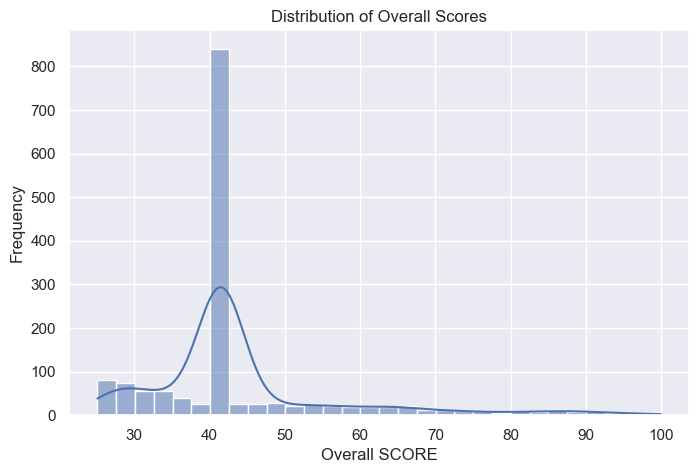

In [14]:
# Distribution of Overall Scores
plt.figure(figsize=(8,5))
sns.histplot(df['Overall SCORE'], kde=True, bins=30)
plt.title('Distribution of Overall Scores')
plt.xlabel('Overall SCORE')
plt.ylabel('Frequency')
plt.show()


C:\Users\Randy Leonard\AppData\Local\Temp\ipykernel_14444\375789917.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y='Institution Name', x='Overall SCORE', data=top20, palette='viridis')


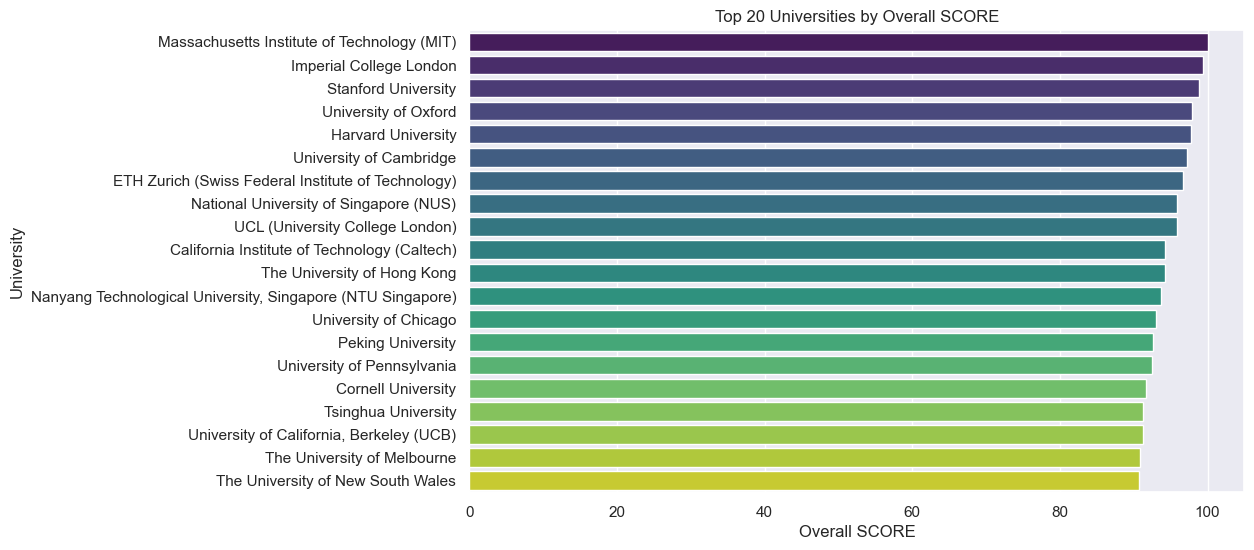

In [15]:
# Top 20 Universities by Overall SCORE
top20 = df.nlargest(20, 'Overall SCORE')
plt.figure(figsize=(10,6))
sns.barplot(y='Institution Name', x='Overall SCORE', data=top20, palette='viridis')
plt.title('Top 20 Universities by Overall SCORE')
plt.xlabel('Overall SCORE')
plt.ylabel('University')
plt.show()


C:\Users\Randy Leonard\AppData\Local\Temp\ipykernel_19588\23622612.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.index, y=top_countries.values, palette='crest')


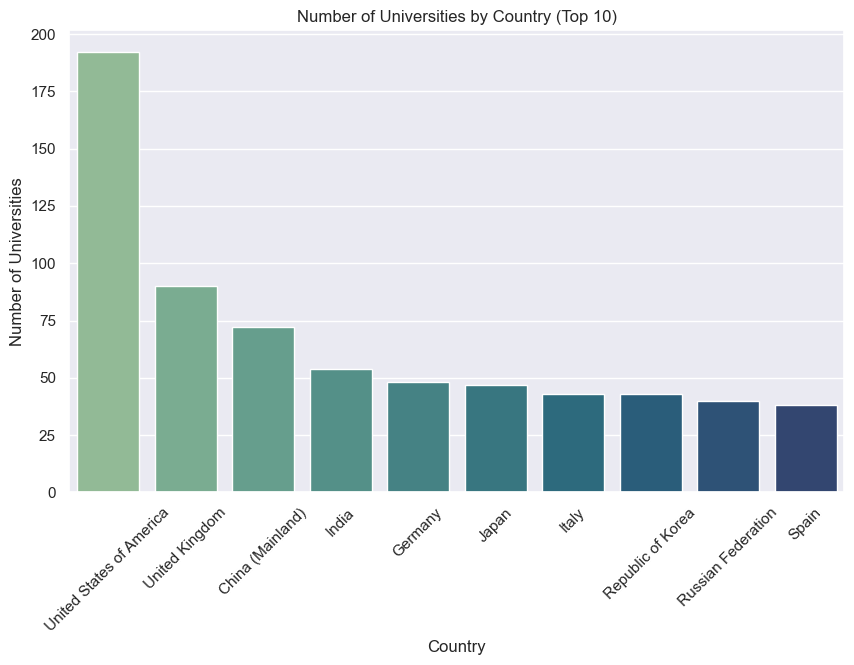

In [15]:
# Number of Universities by Country (Top 10)
top_countries = df['Country/Territory'].value_counts().head(10)
plt.figure(figsize=(10,6))
sns.barplot(x=top_countries.index, y=top_countries.values, palette='crest')
plt.title('Number of Universities by Country (Top 10)')
plt.xlabel('Country')
plt.ylabel('Number of Universities')
plt.xticks(rotation=45)
plt.show()

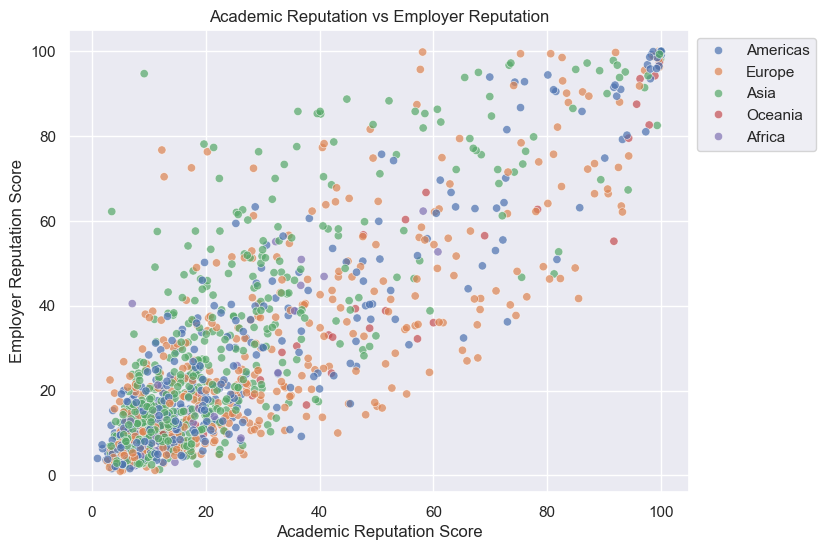

In [16]:
# Scatter Plot: Academic Reputation vs Employer Reputation
plt.figure(figsize=(8,6))
sns.scatterplot(x='AR SCORE', y='ER SCORE', hue='Region', data=df, alpha=0.7)
plt.title('Academic Reputation vs Employer Reputation')
plt.xlabel('Academic Reputation Score')
plt.ylabel('Employer Reputation Score')
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

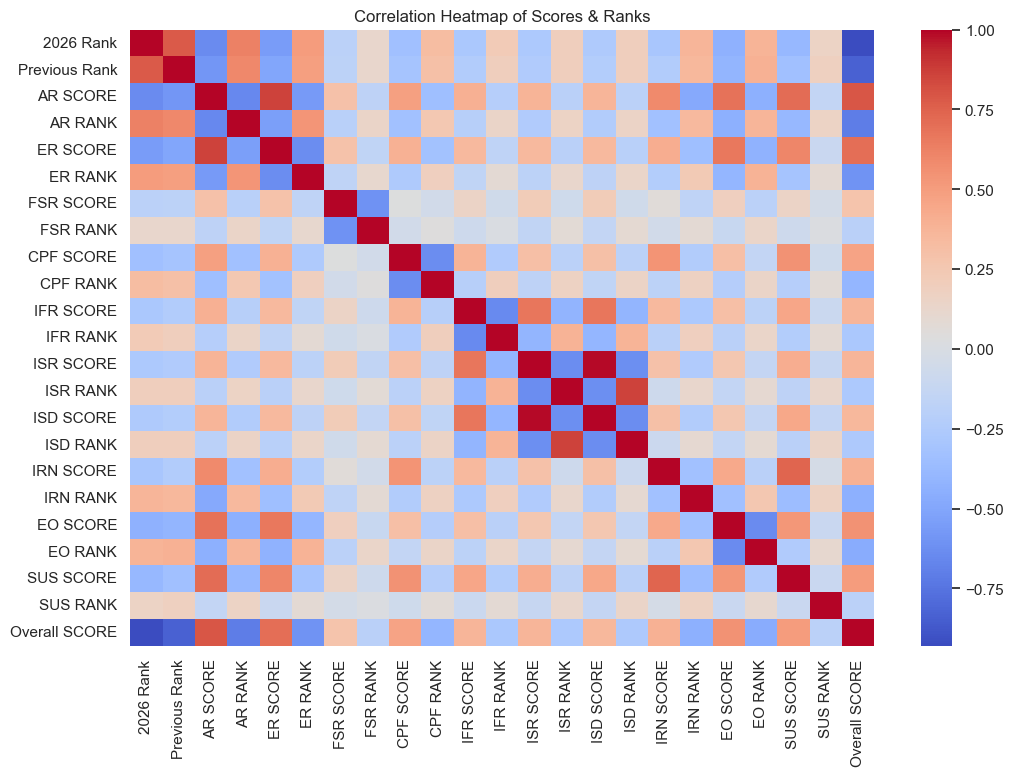

In [17]:
# Correlation Heatmap
plt.figure(figsize=(12,8))
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=False, cmap='coolwarm')
plt.title('Correlation Heatmap of Scores & Ranks')
plt.show()


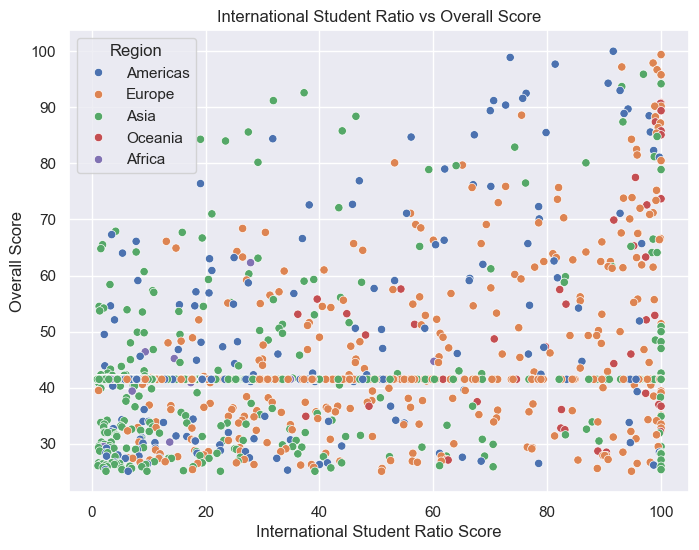

In [18]:
# International Student Ratio vs Overall Score
plt.figure(figsize=(8,6))
sns.scatterplot(x='ISR SCORE', y='Overall SCORE', hue='Region', data=df)
plt.title('International Student Ratio vs Overall Score')
plt.xlabel('International Student Ratio Score')
plt.ylabel('Overall Score')
plt.show()

## Scatter Plot of IRN SCORE vs. Overall SCORE

We want to explore whether universities with **high international research network (IRN SCORE)** also have **high Overall SCORE**.  

- Scatter plot helps visualize correlations or clusters.  
- Highlighting top outliers (extremely high Overall SCORE) and bottom outliers (extremely low Overall SCORE) can show patterns among extreme performers.


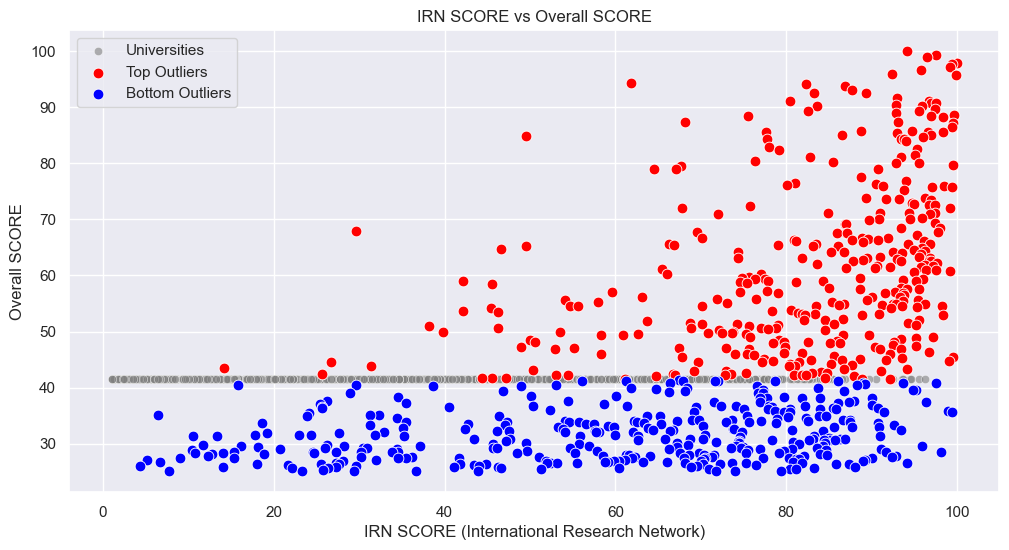

In [19]:
# Scatter plot for IRN SCORE vs Overall SCORE

plt.figure(figsize=(12,6))

# Main scatter plot for all universities
sns.scatterplot(data=df, x='IRN SCORE', y='Overall SCORE', color='gray', alpha=0.6, label='Universities')

# Highlight top Overall SCORE outliers in red
sns.scatterplot(data=df[df['Overall SCORE'] > df['Overall SCORE'].quantile(0.75) + 1.5*(df['Overall SCORE'].quantile(0.75)-df['Overall SCORE'].quantile(0.25))],
                x='IRN SCORE', y='Overall SCORE', color='red', s=60, label='Top Outliers')

# Highlight bottom Overall SCORE outliers in blue
sns.scatterplot(data=df[df['Overall SCORE'] < df['Overall SCORE'].quantile(0.25) - 1.5*(df['Overall SCORE'].quantile(0.75)-df['Overall SCORE'].quantile(0.25))],
                x='IRN SCORE', y='Overall SCORE', color='blue', s=60, label='Bottom Outliers')

plt.title('IRN SCORE vs Overall SCORE')
plt.xlabel('IRN SCORE (International Research Network)')
plt.ylabel('Overall SCORE')
plt.legend()
plt.show()


### Interpretation

- **Positive trend expected**: Universities with stronger international research networks often score higher overall.  
- **Red points (top Overall SCORE outliers)** indicate universities that excel in both IRN SCORE and overall performance.  
- **Blue points (bottom Overall SCORE outliers)** show universities with lower overall performance regardless of IRN SCORE.  

**Why we do this?:**  
- Helps identify **relationships between international collaboration and overall university quality**.  
- Highlights **extreme performers** without removing any data points.


## Key Insights and Actionable Recommendations

- **Insights**:
- 1. Cluster Patterns:
     - Several universities cluster around score thresholds (overall score = 40), indicating bundled rankings.
- 2. Internationalization (ISR, IRN) is a not a strong predictor (alone).
- 3. Varying Ranking Drives: 
     - Faculty/Student ratio, academic reputation, and employer reputation consistently correlate with higher overall scores.
- 4. Regional Trends: 
     - Asia: Higher performance even though Asian universities have a lower ISR
     - America: Mixed performance, reputation-driven success
     - Europe and Oceania: Strong ISR presence, frequently pulled with higher scores

- **Strong correlation** between Academic Reputation and Employer Reputation  
- 1. Countries like USA and UK dominate top rankings  
- 2. Higher International Student Ratio often correlates with higher Overall Scores  
- 3. egional differences in Academic Reputation suggest global disparities in research prestige

- **Recommendations**: 
  
- 1. Prioritize academic reputation, faculty/student ratios, and research output before heavily investing in international student recruitment.
- 2. Implement Balanced Globalization Strategy: Use international student recruitment (ISR, IRN) as a complement, not a substitute, for quality.
- 3. Implement Region-Specific Approaches:
    - Asia/Americas: Leverage academic/research excellence while gradually boosting internationalization.
    - Europe/Oceania: Continue capitalizing on ISR strength but avoid over-dependence on it.
    - Benchmark Against Outliers
- 4. Study institutions with high Overall Scores despite low ISR for best practices in academic and research performance.

- 5. Policy Incentives for Global Mobility:
- How Policymakers Can Support IFR, ISR, IRN
	 1. Visas: Simplify & fast-track for students, faculty, researchers
	 2. Scholarships: Fund inbound & outbound mobility (ex: study abroad)
	 3. Research Collaboration: Seed funding for joint projects & centers
	 4. Integration: Support services for language, mentorship, internships

- 6. Linking Sustainability + Mobility
	1. Green mobility scholarships for SDG (Sustainability Development Goals)
	2. International research hubs focused on climate innovation
	3. Implemented ESG-focused global partnerships




## Conclusion

This analysis provided a deeper understanding of how universities are ranked globally.  
The QS dataset shows that:
- Academic and Employer Reputation are key drivers of overall rankings
- Internationalization metrics (faculty & students) have notable positive associations with scores
- Universities in Asia and the Americas can climb further by adopting selective internationalization without losing focus on academic excellence.
- Countries with long-established higher education systems dominate the top ranks

**Next steps** could include:
- Predictive modeling to forecast future rankings
- Clustering analysis to group universities with similar profiles
- Comparative analysis between regions
- Refine visualizations with trendlines, regression fits, and annotations to clarify actionable findings.
- Identify top-performing universities in each region and analyze their strategic mix of ISR, faculty, and research metrics.
- Create region-specific playbooks for universities aiming to improve their global ranking.


